# Nipah virus (NiV) — does genome composition differ by host?

---

### Why this virus

RSV has no host variation (all 33,040 genomes are human). Nipah jumps from **fruit bats** (the natural host) to **pigs** and **humans**, so the GISAID host field carries real information. The question here: **does a Nipah genome look different when it comes from a bat, a pig or a human?** If the paper's idea (composition shifts with the host the virus lives in) held for Nipah, bat and human genomes would differ in GC or CpG.

### The data

GISAID EpiNiV export: 343 sequences. Merged by `scripts/merge_gisaid.py`; genes cut by `scripts/build_niv_features.py` against the RefSeq Malaysia strain NC_002728.1 (public NCBI sequence).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

os.chdir(os.path.abspath("../.."))          # repo root, so data/ and results/ paths work
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. Host, clade and completeness

In [2]:
m = pd.read_csv("data/processed/NiV/NiV_metadata.tsv", sep="\t", dtype=str)
def host_group(h):
    if h == "Human": return "human"
    if "Sus" in h or "Canis" in h: return "pig/dog"
    if "Pteropus" in h or "Chiroptera" in h: return "bat"
    return "unknown"
m["hostg"] = m.Host.map(host_group)
m["L"] = pd.to_numeric(m["Sequence Length"])
m["year"] = pd.to_numeric(m["Collection date"].str[:4], errors="coerce")
m["country"] = m.Location.str.split(" / ").str[1]
m["complete"] = np.where(m.L >= 17000, "full genome (>=17 kb)", "fragment")
print(m.Host.value_counts().to_string())
print()
print(pd.crosstab(m.hostg, m.complete, margins=True))

Host
Pteropus lylei                   118
Human                            110
Pteropus medius                   52
Chiroptera (bat)                  25
Pteropus vampyrus                 13
unknown                            8
Pteropus hypomelanus               8
Sus scrofa domesticus              7
Other: Canis lupus familiaris      1
Sus scrofa (boar)                  1

complete  fragment  full genome (>=17 kb)  All
hostg                                         
bat            197                     19  216
human           36                     74  110
pig/dog          0                      9    9
unknown          4                      4    8
All            237                    106  343


**Most bat sequences are short fragments.** Only 19 of the 216 bat genomes are full-length, against 74 of 110 from humans. That matters: a fragment covers one gene region, so it can only be compared with other sequences over the **same** region.

In [3]:
print(pd.crosstab(m.country, m.hostg, margins=True))
print()
print("collection year known for", m.year.notna().sum(), "of", len(m), "(missing mostly bat sequences)")
print(m.groupby("hostg").year.agg(["min", "max", "count"]))

hostg       bat  human  pig/dog  unknown  All
country                                      
Bangladesh   39     88        0        3  130
Cambodia     31      0        0        0   31
India        30     15        0        0   45
Indonesia     7      0        0        0    7
Malaysia      5      7        9        2   23
Sri Lanka     3      0        0        0    3
Thailand    101      0        0        0  101
All         216    110        9        5  340

collection year known for 261 of 343 (missing mostly bat sequences)
            min     max  count
hostg                         
bat      2003.0  2023.0    143
human    1998.0  2025.0    108
pig/dog  1999.0  1999.0      8
unknown  2014.0  2014.0      2


## 2. Host and timing: lineages BD1, BD2, BD3

GISAID labels the Bangladesh/India clade (NiV-B) as BD1, BD2 and BD3. This is the "host plus timing" information that could separate sporadic from sustained circulation.

In [4]:
m["lineage"] = m.Lineage.fillna("none")
t = m.groupby("lineage").apply(lambda g: pd.Series({
    "genomes": len(g), "from bats": (g.hostg == "bat").sum(), "from humans": (g.hostg == "human").sum(),
    "first year": g.year.min(), "last year": g.year.max()}), include_groups=False)
t

,genomes,from bats,from humans,first year,last year
lineage,,,,,
BD1,54.0,24.0,29.0,2004.0,2020.0
BD2,189.0,124.0,63.0,2004.0,2025.0
BD3,37.0,26.0,11.0,2018.0,2025.0
none,63.0,42.0,7.0,1998.0,2021.0


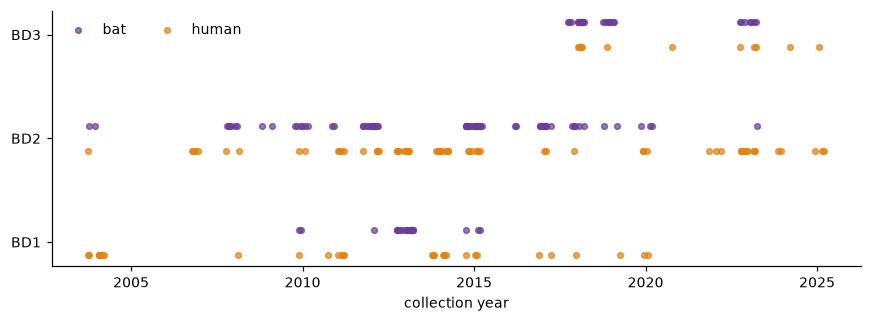

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
d = m[m.year.notna() & m.lineage.isin(["BD1", "BD2", "BD3"]) & m.hostg.isin(["bat", "human"])]
cols = {"bat": "#6A3D9A", "human": "#E08214"}
for i, lin in enumerate(["BD1", "BD2", "BD3"]):
    for h, off in (("bat", .12), ("human", -.12)):
        y = d[(d.lineage == lin) & (d.hostg == h)].year
        ax.scatter(y + np.random.default_rng(0).uniform(-.25, .25, len(y)), np.full(len(y), i + off), s=14, color=cols[h], alpha=.7,
                   label=h if i == 0 else None)
ax.set_yticks(range(3)); ax.set_yticklabels(["BD1", "BD2", "BD3"]); ax.set_xlabel("collection year")
ax.legend(frameon=False, ncol=2, loc="upper left"); plt.tight_layout()
fig.savefig("results/figures/niv_lineage_host_timeline.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.** BD2 runs from 2004 to 2025 and appears in **both bats and humans** across that whole span; BD1 and BD3 are the same pattern over shorter periods. That is what a persistent bat reservoir with repeated human spillover looks like: the lineage is sustained in bats, and each human outbreak is a short dead-end. It is **consistent with** that picture, not proof: 73 of the 216 bat sequences have no collection year, and the human genomes come from only a few outbreaks.

## 3. Composition by host

For each gene, genomes are kept only if they cover at least 90% of the reference gene (so every sequence is compared over the same region). GC3 additionally needs a gene that starts with ATG and reads in frame.

In [6]:
d = pd.read_csv("data/processed/NiV/NiV_gene_features.tsv", sep="\t")
d["hostg"] = d.Host.map(lambda h: host_group(h) if isinstance(h, str) else "unknown")
d["clade"] = d.Clade.str.extract(r"\((.*)\)")
order = ["N", "M", "F", "G", "L", "GENOME"]
print(pd.crosstab(d.gene, [d.clade, d.hostg]).reindex(order))

clade  NiV-B               NiV-M                      
hostg    bat human unknown   bat human pig/dog unknown
gene                                                  
N         28    82       1     9     7       9       3
M         18    67       1     3     7       9       3
F         18    68       1     3     7       9       4
G         18    67       1     5     7       9       4
L         18    67       1     3     7       9       3
GENOME    18    67       1     1     7       9       3


In [7]:
# NiV-B only, where bats and humans can be compared like for like
b = d[d.clade == "NiV-B"]
tab = b.groupby(["gene", "hostg"])[["gc_content", "oe_CG", "oe_TA", "gc3"]].mean().round(4)
cmp = tab.unstack("hostg")
out = pd.DataFrame({
    "GC bat": cmp[("gc_content", "bat")], "GC human": cmp[("gc_content", "human")],
    "CpG O/E bat": cmp[("oe_CG", "bat")], "CpG O/E human": cmp[("oe_CG", "human")],
    "GC3 bat": cmp[("gc3", "bat")], "GC3 human": cmp[("gc3", "human")]}).reindex(order)
out["GC diff"] = (out["GC bat"] - out["GC human"]).round(4)
out["CpG diff"] = (out["CpG O/E bat"] - out["CpG O/E human"]).round(4)
out

,GC bat,GC human,CpG O/E bat,CpG O/E human,GC3 bat,GC3 human,GC diff,CpG diff
gene,,,,,,,,
N,0.4533,0.4532,0.4033,0.3941,0.3973,0.3972,0.0001,0.0092
M,0.4280,0.4285,0.4146,0.4160,0.4618,0.4613,-0.0005,-0.0014
F,0.3845,0.3845,0.4375,0.4470,0.3845,0.3848,0.0000,-0.0095
G,0.4024,0.4019,0.4062,0.3925,0.3972,0.3986,0.0005,0.0137
L,0.3806,0.3806,0.4680,0.4638,0.3694,0.3704,0.0000,0.0042
GENOME,0.3856,0.3854,0.4505,0.4408,NaN,NaN,0.0002,0.0097


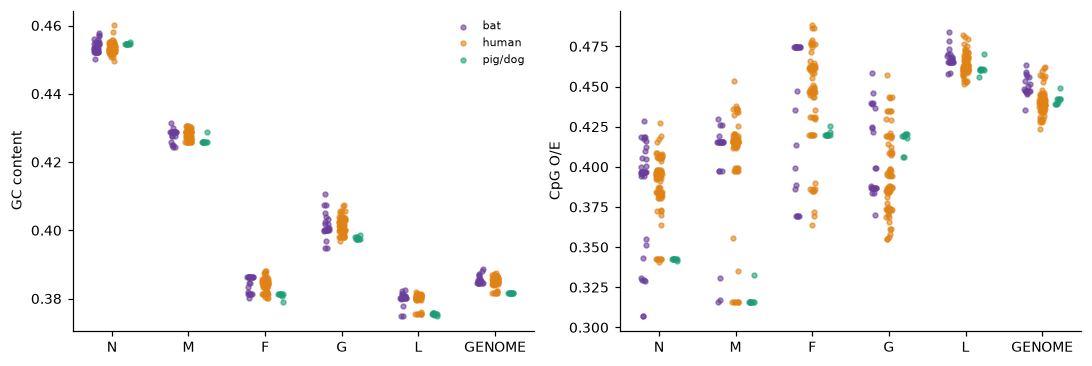

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
cols = {"bat": "#6A3D9A", "human": "#E08214", "pig/dog": "#1B9E77"}
for ax, col, lab in zip(axs, ["gc_content", "oe_CG"], ["GC content", "CpG O/E"]):
    for i, g in enumerate(order):
        for h, off in (("bat", -.2), ("human", 0), ("pig/dog", .2)):
            v = d[(d.gene == g) & (d.hostg == h)][col]
            if len(v):
                ax.scatter(np.full(len(v), i + off) + np.random.default_rng(1).uniform(-.04, .04, len(v)), v, s=10, color=cols[h], alpha=.6,
                           label=h if i == 0 else None)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_ylabel(lab)
axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); fig.savefig("results/figures/niv_host_composition.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.** Bat and human genomes are **indistinguishable in composition**: whole-genome GC is 0.386 in bats and 0.385 in humans, CpG O/E 0.450 and 0.441. The largest differences are 0.0005 in GC and 0.014 in CpG O/E, far smaller than the gaps between genes (e.g. N is 45% GC, L is 38%).

This is the expected result for a virus that is the **same lineage** in bats and in the humans they infect: a human outbreak starts from a bat strain, and it ends before any composition change can build up. Nipah's overall CpG O/E (about 0.44) is moderately suppressed: far less than RSV-A's NS1 (0.016), similar to most RSV genes (0.2-0.4).

## 4. What this means

| Question | Answer |
|---|---|
| Does composition differ by host? | **No.** Bat and human GC differ by at most 0.0005 and CpG O/E by at most 0.014, per gene. |
| Is there host and timing information? | **Yes, but thin.** BD2 spans 2004-2025 in both bats and humans, which fits a persistent bat reservoir with repeated spillover. |
| Can the RSV trend pipeline run? | **No.** There are 106 full genomes, and no lineage reaches the 200 genomes over 5 years that the trend analysis needs. |

**Limits.** 343 sequences, most of them fragments; 82 have no collection year; human genomes come from a handful of outbreaks (Bangladesh alone gives 88), so they are near-copies of each other, and counting them as independent overstates the evidence. The result above is therefore a **negative**, not a failed analysis: Nipah does not show a host-linked composition signal in this data.